In [18]:
import pandas as pd

df = pd.read_csv('/content/water_potability.csv')
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


# this to check the Number of rows and columns as stateted below:
 3,276 rows= water samples

 10 columns= 9 water quality measurement + 1 target column

In [19]:
df.shape

(3276, 10)

#This is to check the column names

In [20]:
df.columns

Index(['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity',
       'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability'],
      dtype='object')

#CHECK FOR MISSING DATA
this tells you how many missing values each column has

In [21]:
df.isnull().sum()

,0
ph,491
Hardness,0
Solids,0
Chloramines,0
Sulfate,781
Conductivity,0
Organic_carbon,0
Trihalomethanes,162
Turbidity,0
Potability,0


#GET INFORMATION ABOUT THE DATASET
This shows the data types and number of non empty values

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


#DATASET DESCRIPTION
The water potability Dataset contains 3,276 rows and 10 columns. Each row represents a water samples, while the columns contain measurements of its quality, including;
ph
hardness
dissolved solids
chloramines
sulfate
conductivity
organic
carbon
trihalomethanes
turbidity.
The final column, POTABILITY indicates whether the water is suitable for drinking, where 1 means potable and 0 means not potable.

SOURCE: kaggle- water potability dataset
http://www.kaggle.com/dataset/adityakadiwal/water-potability



NOTE: the dataset has missing values in ph(491), sulfate(781) and Trihalomethanes(162), which will be needed to be addressed in the data cleaning stage.

 # DATA CLEANING
In this section, the dataset will be checked and cleaned
The cleaning process will focus on:
1.Duplicate rows and columns
2.Missing values
3.Data types
4.Outliers
5.Irrelevant columns



# CHECK DUPLICATE ROWS
check the number of duplicate rows

In [23]:
duplicate_rows = df.duplicated().sum()
print(f'Number of duplicate rows:{duplicate_rows}')

Number of duplicate rows:0


There are no duplicate rows in all 3,276 rows

# CHECK DUPLICATE COLUMNS
check the number of duplicate columns

In [24]:
duplicate_columns = df.columns.duplicated().sum()
df.T.duplicated().sum()
print(f'Number of duplicate columns:{duplicate_columns}')

Number of duplicate columns:0


There are no duplicate columns

# CHECK MISSING VALUES

In [25]:
# Check the number of missing values in each column
import pandas as pd
df = pd.read_csv('water_potability.csv')
df.isnull().sum()


,0
ph,491
Hardness,0
Solids,0
Chloramines,0
Sulfate,781
Conductivity,0
Organic_carbon,0
Trihalomethanes,162
Turbidity,0
Potability,0


# FIXING MISSING VALUES
Filling with Median

In [26]:
import pandas as pd

df = pd.read_csv('water_potability.csv')
cols = ['ph', 'Sulfate', 'Trihalomethanes']
df[cols] = df[cols].fillna(df[cols].median())


# CHECK IF MISSING VALUES ARE GONE

In [27]:
df.isna().sum()

,0
ph,0
Hardness,0
Solids,0
Chloramines,0
Sulfate,0
Conductivity,0
Organic_carbon,0
Trihalomethanes,0
Turbidity,0
Potability,0


After median imputation, the dataset is checked again to confirm that the missing values have been addressed.

# DATASET INFORMATION / DATA TYPES

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               3276 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          3276 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3276 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


# OUTLIERS
Detect outliers using the IQR method

In [29]:
feature_columns = df.select_dtypes(include='number').columns.tolist()
print(feature_columns)

['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability']


In [30]:
outlier_summary = []

for column in feature_columns:
  Q1 = df[column].quantile(0.25)
  Q3 = df[column].quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

  outlier_count = len(outliers)
  outlier_percentage = (outlier_count / len(df)) * 100

  outlier_summary.append({
      'Column': column,
      'Q1': Q1,
      'Q3': Q3,
      'IQR': IQR,
      'Lower Bound': lower_bound,
      'Upper Bound': upper_bound,
      'Outlier Count': outlier_count,
      'Outlier Percentage': outlier_percentage
     })
  outlier_summary_df = pd.DataFrame(outlier_summary)

outlier_summary_df


,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,ph,6.277673,7.870050,1.592377,3.889107,10.258615,142,4.334554
1,Hardness,176.850538,216.667456,39.816918,117.125160,276.392834,83,2.533578
2,Solids,15666.690297,27332.762127,11666.071830,-1832.417449,44831.869873,47,1.434676
3,Chloramines,6.127421,8.114887,1.987466,3.146221,11.096086,61,1.862027
4,Sulfate,317.094638,350.385756,33.291119,267.157960,400.322434,264,8.058608
5,Conductivity,365.734414,481.792304,116.057890,191.647579,655.879140,11,0.335775
6,Organic_carbon,12.065801,16.557652,4.491850,5.328026,23.295427,25,0.763126
7,Trihalomethanes,56.647656,76.666609,20.018954,26.619225,106.695040,54,1.648352
8,Turbidity,3.439711,4.500320,1.060609,1.848797,6.091233,19,0.579976
9,Potability,0.000000,1.000000,1.000000,-1.500000,2.500000,0,0.000000


A simple summary of potential outliers

In [31]:
outlier_summary_df[['Column', 'Outlier Count', 'Outlier Percentage']].round(2)

,Column,Outlier Count,Outlier Percentage
0,ph,142,4.33
1,Hardness,83,2.53
2,Solids,47,1.43
3,Chloramines,61,1.86
4,Sulfate,264,8.06
5,Conductivity,11,0.34
6,Organic_carbon,25,0.76
7,Trihalomethanes,54,1.65
8,Turbidity,19,0.58
9,Potability,0,0.00


The IQR method flagged potential outliers in all nine numerical variables, with the highest propotions in Sulfate (8.06%) and ph (4.33%).All other variableshad under 3%.
This observations were not automatically deleted because an extreme water quality measurement is not necessarily an incorrect measurement or error,extreme values are often real measurement(A contaminated sample,for example)

# IRRELEVANT COLUMNS
No column is considerd irrelevant. The dataset contains nine input features,all of which are physicochemical water quality measurements relevant to assessing potability.
No column was removed because none of the nine features is constant,an identifier,or duplicated.Futhermore,the highest pairwise correlation between features was about 0.15,indicating no meaningful redundancy.Although individual linear correlation with potability are weak,this does not justify removal,so all features are retained for modelling and their contribution will be assessed through model evaluation.

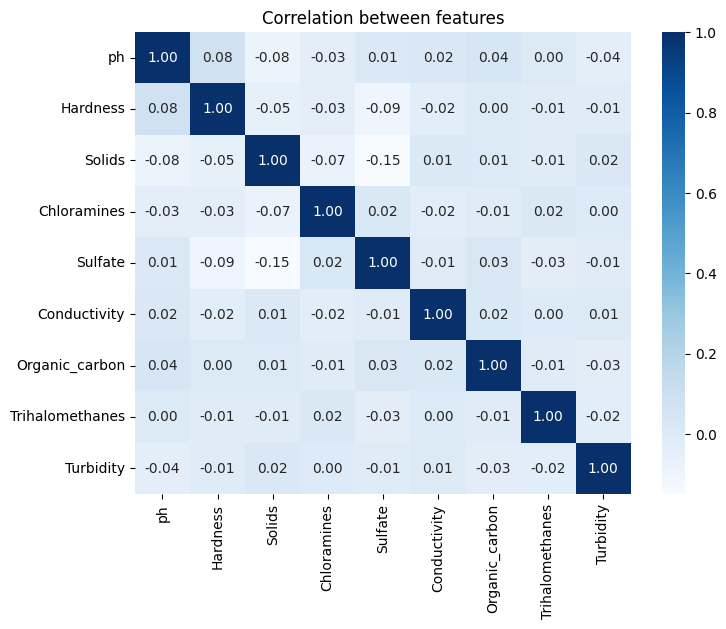

Highest pairwise correlation: 0.15


In [32]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

corr = df.drop('Potability', axis=1).corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues")
plt.title("Correlation between features")
plt.show()

mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
print("Highest pairwise correlation:", round(corr.where(mask).abs().max().max(), 2))

The correlations between features are all very small. The strongest is between Solids and Sulfate at about -0.15. This means no two features carry the same information, so we kept all nine.

# DATA PROCESSING

In this section the cleaned data is prepered for modeling. We will be going through some steps which are:

1. Seperating the features from the target variable
2. Encoding Categorigorical variables
3. Check the class balance of the target
4. Spliting the data into two sets

  a. Training Set

  b. Test Set

5. Scaling the Numerical Features
6. Consideering Feature Engineering

## SEPARATING FEATURES AND TARGET

The dataset is split into two parts. `X` holds the nine water quality measurements the model will learn from, and `y` holds the `Potability` column, which is the value we want to predict (1 = potable, 0 = not potable). Keeping the target separate stops the model from seeing the answer during training.

In [33]:
X = df.drop('Potability', axis=1)
y = df['Potability']

print(X.shape)
print(y.shape)

(3276, 9)
(3276,)


## ENCODING CATEGORICAL VARIABLES

All nine features are numeric (float64), and the target `Potability` is already stored as 0 and 1. There are no categorical columns, so no label encoding or one-hot encoding is needed.

## CHECKING CLASS BALANCE

Before splitting the data, we check how the two classes are distributed. If one class is much larger than the other, a model can reach a high accuracy by mostly predicting the majority class, and this affects how the split and the evaluation metrics should be handled.

In [34]:
# Assisted by Claude, adapted for this dataset
print(y.value_counts())
print(y.value_counts(normalize=True))

Potability
0    1998
1    1278
Name: count, dtype: int64
Potability
0    0.60989
1    0.39011
Name: proportion, dtype: float64


Observation: 60.99% of the samples (1,998) are not potable (0) and 39.01% (1,278) are potable (1). The classes are imbalanced, but not severely. Because of this, the train/test split will be stratified so both sets keep the same proportions, and accuracy alone will not be enough to judge the models. Precision, recall and F1 will also be reported.

## TRAIN/TEST SPLIT

The data is split into 80% for training and 20% for testing. 80/20 is a common choice because it leaves enough data to train on while keeping a test set large enough (656 samples) to evaluate the models reliably. The split is stratified on `Potability` so both sets keep the same class proportions (about 61% / 39%), and `random_state=42` is fixed so the results can be reproduced.

In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(2620, 9) (656, 9)
Potability
0    0.609924
1    0.390076
Name: proportion, dtype: float64
Potability
0    0.609756
1    0.390244
Name: proportion, dtype: float64


Observation: the training set has 2,620 samples and the test set has 656. Both keep the original class proportions (about 61% non-potable and 39% potable), which confirms the stratified split worked.

## SCALING THE FEATURES

The features are on very different scales. For example, Solids is in the tens of thousands while Chloramines is around 7. Models that depend on distances or gradients (logistic regression, SVM, KNN, neural networks) can be dominated by the large-valued features if the data is left as it is.

StandardScaler is used here. It rescales each feature to have a mean of 0 and a standard deviation of 1. I chose StandardScaler because the data has outliers (about 8% in Sulfate and 4% in ph). MinMaxScaler uses the smallest and biggest values, so a few extreme readings would squash all the normal ones together. StandardScaler is less affected by that. We kept the extreme values because they may be real readings.

The scaler is fitted on the training set only and then applied to the test set. Fitting it on the full data would let information from the test set leak into training.

In [36]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.shape, X_test_scaled.shape)
print(X_train_scaled.mean(axis=0).round(2))
print(X_train_scaled.std(axis=0).round(2))

(2620, 9) (656, 9)
[ 0. -0.  0.  0.  0.  0. -0. -0. -0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1.]


## FEATURE ENGINEERING

Feature engineering was considered but not applied. All nine features are already direct physicochemical measurements, and we did not combine them because the features have very weak links with each other (the highest correlation is about 0.15), and we had no clear water-science reason to build a ratio or a sum. Adding features without a clear meaning would increase complexity without a justified benefit.

## PREPROCESSING SUMMARY

The data is now ready for modelling. The variables to use are:
- `X_train_scaled`, `y_train`: training features (2,620 samples) and labels
- `X_test_scaled`, `y_test`: test features (656 samples) and labels

Median imputation was applied during data cleaning, before the train/test split. This means the medians were calculated using the full dataset, which allows a small amount of information from the test set to influence training. Median imputation filled 1,434 missing values, which is about 4.4% of all values in the dataset (about 14.6% of the three columns that had gaps). The effect is expected to be small, but it is a limitation of this pipeline.

# MODELLING

## Model 1: Random Forest Classifier

In this section, we develop our first machine learning model to predict the potability of water samples using the water-quality measurements available in our dataset.

The target variable is "Potability", which represents a binary classification problem. A value of 0 indicates that a sample is labelled not potable, while a value of 1 indicates that a sample is labelled potable.

We selected the Random Forest Classifier as our first modelling approach. Random Forest is an ensemble learning algorithm that combines the predictions of multiple decision trees. Each tree is trained using a sample of the training data and a randomly selected subset of features. For classification, the individual tree predictions are combined to produce the final prediction.

We chose this algorithm because water potability may depend on relationships between several measurements rather than on a single variable. Random Forest can learn nonlinear relationships and interactions between features without requiring us to assume that the relationship between each measurement and potability is linear.

This model will serve as a baseline for our modelling experiments. Its performance can subsequently be compared with that of a second algorithm to determine which approach performs better on the held-out test data.

## Model Configuration and Hyperparameters

We configure the Random Forest Classifier using the following parameters:

- "n_estimators=200": The model builds 200 decision trees. Using multiple trees helps the ensemble combine different learned patterns and can reduce the instability of relying on a single decision tree.
- "max_depth= None": The trees are allowed to grow until other stopping conditions are met. This allows the model to learn complex relationships, although excessive tree depth can increase overfitting risk.
- "min_samples_split=2": A node must contain at least two samples before it can be considered for splitting. This is the standard minimum and allows relatively detailed trees.
- "min_samples_leaf=1": A leaf node may contain one sample. This gives the trees flexibility but can also allow them to learn noise in the training data.
- "class_weight='balanced'": The algorithm adjusts class weights inversely according to class frequencies in the training data. This is worth testing because the dataset contains different numbers of samples in the two potability classes.
- "random_state=42": This fixes the random seed to make the experiment reproducible under the same software and data conditions.
- "n_jobs=-1": The algorithm uses all available CPU cores where supported, helping to speed up training.

These are initial hyperparameter choices rather than guaranteed optimal values. We will use the evaluation results to understand the model's performance and identify possible improvements.

Random Forest does not require numerical feature scaling in the way that distance-based algorithms or many gradient-based models do. We therefore retain the preprocessing established in the preceding section rather than adding an unnecessary scaling step specifically for this model.

In [37]:
# Model 1: Random Forest Classifier
# for the water potability capstone dataset.

import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Confirm that the preceding preprocessing section has run.
required_variables = ["X_train", "X_test", "y_train", "y_test"]

missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        "Run the preprocessing and train-test split sections first. "
        f"Missing variables: {missing_variables}"
    )

# Confirm that the training and testing sets are not empty.
if len(X_train) == 0 or len(X_test) == 0:
    raise ValueError("The training and testing sets must not be empty.")

# Define the model as a pipeline.
# Median imputation handles any remaining missing numerical values.
# It is fitted only on the training data, preventing information leakage.
random_forest_model = Pipeline([

     # safety step only; gaps were already filled earlier
      (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=200,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])

# Train the model using the training data only.
random_forest_model.fit(X_train, y_train)

print("Random Forest Classifier trained successfully.")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print("Number of trees:", 200)
print("Maximum tree depth: None")
print("Class weighting: balanced")

Random Forest Classifier trained successfully.
Training samples: 2620
Testing samples: 656
Number of trees: 200
Maximum tree depth: None
Class weighting: balanced


## Generating Predictions

After training the Random Forest Classifier, we use it to predict the potability labels of the samples in the test set.

The test set is kept separate from the training process so that it can provide an independent assessment of how well the model generalises to previously unseen samples.

The classifier produces a predicted class for each test sample. These predictions will be used in the evaluation section to calculate the required classification metrics and examine the errors made by the model.

In [38]:
# Generate predictions for the held-out test set.
y_pred_rf = random_forest_model.predict(X_test)

print("Predictions generated successfully.")
print("Number of test predictions:", len(y_pred_rf))
print("\nFirst 20 predicted labels:")
print(y_pred_rf[:20])

Predictions generated successfully.
Number of test predictions: 656

First 20 predicted labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]


## Evaluation

### Evaluating Model 1: Random Forest Classifier

We evaluate the Random Forest Classifier using the held-out test set. We report accuracy, precision, recall, and F1 score for both classes, alongside a confusion matrix.

Accuracy measures the proportion of all test predictions that are correct. Precision measures how many predictions for a particular class are correct, while recall measures how many actual samples belonging to that class are identified by the model. The F1 score combines precision and recall into a single measure using their harmonic mean.

We report these metrics for both potability classes because accuracy alone may not reveal whether the model performs well for one class but poorly for the other. This is especially relevant when the target classes have different frequencies.

The confusion matrix provides a more detailed view of correct and incorrect predictions. These results will later be compared with those from our second model using the same test set.

RANDOM FOREST CLASSIFIER — TEST RESULTS
---------------------------------------------
Accuracy:  0.6707
Precision: 0.6818
Recall:    0.2930
F1 Score:  0.4098

Classification Report:
                 precision    recall  f1-score   support

Not Potable (0)       0.67      0.91      0.77       400
    Potable (1)       0.68      0.29      0.41       256

       accuracy                           0.67       656
      macro avg       0.68      0.60      0.59       656
   weighted avg       0.67      0.67      0.63       656



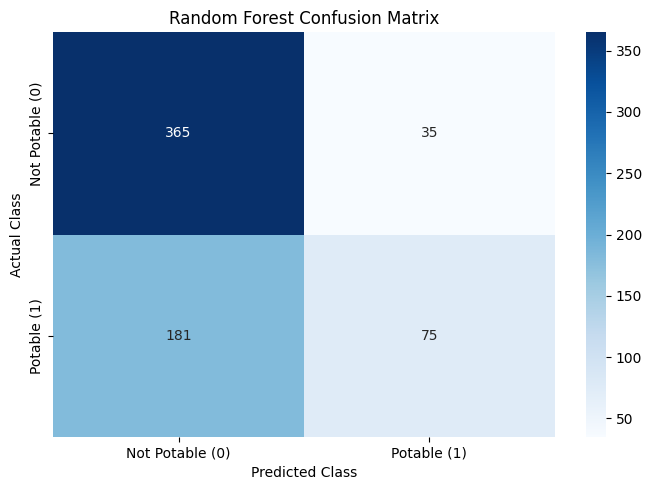

In [39]:

# Evaluate Model 1 on the held-out test set.

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
        classification_report,
            confusion_matrix,
                ConfusionMatrixDisplay,
                    precision_score,
                        recall_score,
                            f1_score)
# Calculate overall metrics.
accuracy_rf = accuracy_score(y_test, y_pred_rf)

precision_rf = precision_score(
                                y_test, y_pred_rf,
                                    pos_label=1,
                                        zero_division=0
                                        )

recall_rf = recall_score(
                                            y_test, y_pred_rf,
                                                pos_label=1,
                                                    zero_division=0
                                                    )

f1_rf = f1_score(
                                                        y_test, y_pred_rf,
                                                            pos_label=1,
                                                                zero_division=0
                                                                )

print("RANDOM FOREST CLASSIFIER — TEST RESULTS")
print("-" * 45)
print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1 Score:  {f1_rf:.4f}")

print("\nClassification Report:")
print(
                                                                    classification_report(
                                                                            y_test,
                                                                                    y_pred_rf,
                                                                                            labels=[0, 1],
                                                                                                    target_names=["Not Potable (0)", "Potable (1)"],
                                                                                                            zero_division=0
                                                                                                                )
                                                                                                                )

# Build the confusion matrix with a consistent class order.
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])

plt.figure(figsize=(7, 5))
sns.heatmap(
                                                                                                                    cm_rf,
                                                                                                                        annot=True,
                                                                                                                            fmt="d",
                                                                                                                                cmap="Blues",
                                                                                                                                    xticklabels=["Not Potable (0)", "Potable (1)"],
                                                                                                                                        yticklabels=["Not Potable (0)", "Potable (1)"]
                                                                                                                                        )

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

### Interpretation of Random Forest Results

The Random Forest achieved a test accuracy of 0.6707. For the potable class, precision was 0.6818, recall was 0.2930 and F1 was 0.4098. The confusion matrix shows 365 not-potable samples and 75 potable samples classified correctly. It incorrectly classified 35 not-potable samples as potable (false positives) and 181 potable samples as not potable (false negatives).

The model is cautious. It predicts "not potable" most of the time, so it rarely calls unsafe water safe, but it misses most of the potable samples.

## Feature Importance Analysis

Random Forest provides a feature-importance measure based on how much each feature contributes to reducing impurity across the trees. We use this measure to examine which water-quality measurements the trained model relies on most.

This analysis can help identify potentially informative variables and guide future experiments. However, feature importance should be interpreted cautiously because correlated features can share importance, and the measure does not establish a causal relationship between a measurement and water potability.

        Feature  Importance
             ph    0.129659
        Sulfate    0.126579
       Hardness    0.118491
    Chloramines    0.117531
         Solids    0.113358
   Conductivity    0.101510
      Turbidity    0.099174
 Organic_carbon    0.096901
Trihalomethanes    0.096796


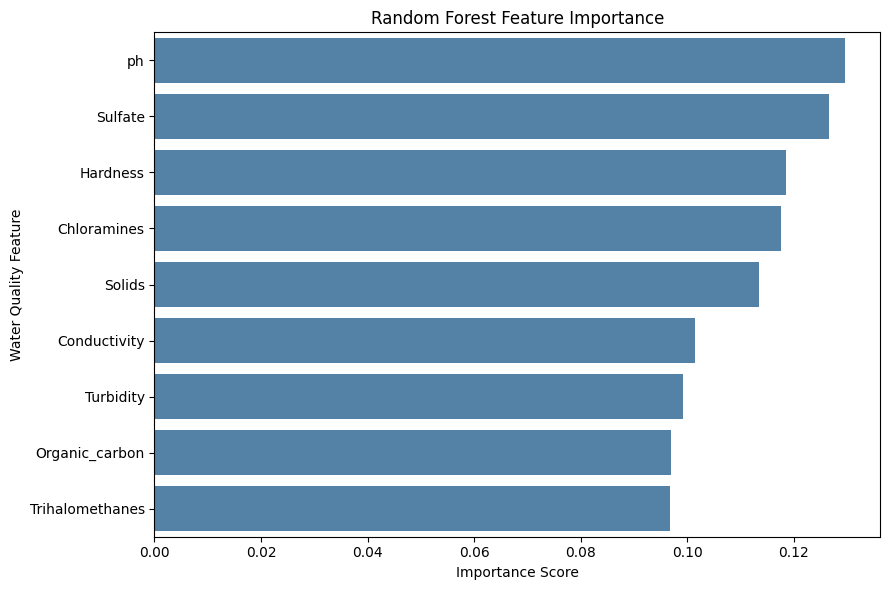

In [40]:
# Extract feature importance from the fitted Random Forest model.

feature_names = list(X_train.columns)

rf_classifier = random_forest_model.named_steps["classifier"]

importance_df = pd.DataFrame({
    "Feature": feature_names,
        "Importance": rf_classifier.feature_importances_
}).sort_values(
            by="Importance",
                ascending=False)

print(importance_df.to_string(index=False))

plt.figure(figsize=(9, 6))

sns.barplot(
                    data=importance_df,
                        x="Importance",
                            y="Feature",
                                color="steelblue"
                                )

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Water Quality Feature")
plt.tight_layout()
plt.show()

## Model 2: Support Vector Machine (SVM)

For the second model we use a Support Vector Classifier (SVC) with an RBF (radial basis function) kernel. An SVM looks for the boundary that separates the two classes with the widest possible gap (margin) between them. The RBF kernel allows that boundary to curve, so the model can separate classes that a straight line cannot.

Why an SVM was chosen as the comparison model:

- **It works differently from Random Forest.** Random Forest splits the data one feature at a time and averages the votes of many trees. The SVM instead measures distances between samples using all nine features at once. Comparing two different approaches tells us more than comparing two tree-based models.
- **The relationships are not linear.** The EDA showed only weak linear correlation between each feature and potability, so a straight-line boundary is unlikely to work well. The RBF kernel can learn a non-linear boundary.
- **The dataset size suits it.** SVMs become slow on very large datasets, but 2,620 training samples is well within what they handle comfortably.
- **It makes use of the scaled data.** Because the SVM depends on distances, features with large values (such as Solids) would dominate if left unscaled. This model therefore uses `X_train_scaled` and `X_test_scaled` from the preprocessing section.

### Model Configuration and Hyperparameters

We configure the SVM using the following parameters:

- **`kernel='rbf'`**: uses the radial basis function kernel, which allows a curved decision boundary.
- **`C=1.0`**: controls the trade-off between a wide, smooth margin and classifying every training sample correctly. A small C tolerates more training errors and gives a smoother boundary; a large C fits the training data more tightly and increases the risk of overfitting. 1.0 is the standard default.
- **`gamma='scale'`**: controls how far the influence of a single training sample reaches. A small gamma gives a smooth boundary; a large gamma gives a very local, irregular boundary that can overfit. `'scale'` sets it automatically from the data as 1 / (number of features × variance of X).
- **`class_weight='balanced'`**: gives more weight to the smaller potable class, as in Model 1, so that both models handle the imbalance in the same way.
- **`random_state=42`**: fixes the random seed so the results can be reproduced.

As with Model 1, these are initial settings chosen by hand rather than tuned values. Keeping both models untuned means they are compared on equal terms. The model is trained on the training set only; the test set is kept for evaluation.

In [41]:
# Model 2: Support Vector Machine (SVM) with an RBF kernel
from sklearn.svm import SVC

# The SVM uses the scaled features from the preprocessing section.
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    class_weight="balanced",
    random_state=42
)

# Train the model using the training data only.
svm_model.fit(X_train_scaled, y_train)

print("SVM trained successfully.")
print(f"Training samples: {len(X_train_scaled)}")
print(f"Testing samples: {len(X_test_scaled)}")
print("Kernel: rbf")
print("C: 1.0")
print("Gamma: scale")
print("Class weighting: balanced")

SVM trained successfully.
Training samples: 2620
Testing samples: 656
Kernel: rbf
C: 1.0
Gamma: scale
Class weighting: balanced


### Generating Predictions

The trained SVM predicts the potability label for each of the 656 test samples. The predictions are stored in `y_pred_svm` so they can be evaluated and compared with Model 1 (`y_pred_rf`) in the Evaluation and Model Comparison section.

In [42]:
# Generate predictions for the held-out test set.
y_pred_svm = svm_model.predict(X_test_scaled)

print("Predictions generated successfully.")
print("Number of test predictions:", len(y_pred_svm))
print("\nPredicted class counts:")
print(pd.Series(y_pred_svm).value_counts().rename({0: "Not Potable (0)", 1: "Potable (1)"}))
print("\nFirst 20 predicted labels:")
print(y_pred_svm[:20])

Predictions generated successfully.
Number of test predictions: 656

Predicted class counts:
Not Potable (0)    405
Potable (1)        251
Name: count, dtype: int64

First 20 predicted labels:
[0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 1 1 1 0 1]


## Evaluating Model 2: SVM

The SVM's predictions on the 656 test samples are compared with the true labels. Because the classes are imbalanced (about 61% non-potable and 39% potable), accuracy alone can be misleading, so precision, recall and F1 are reported for each class, along with a confusion matrix.

In [43]:
from sklearn.metrics import accuracy_score, classification_report

acc_svm = accuracy_score(y_test, y_pred_svm)
print(f"Accuracy: {acc_svm:.4f}\n")
print(classification_report(
    y_test, y_pred_svm,
    target_names=["Not Potable (0)", "Potable (1)"]
))

Accuracy: 0.6204

                 precision    recall  f1-score   support

Not Potable (0)       0.69      0.69      0.69       400
    Potable (1)       0.51      0.50      0.51       256

       accuracy                           0.62       656
      macro avg       0.60      0.60      0.60       656
   weighted avg       0.62      0.62      0.62       656



### Confusion matrix

The confusion matrix shows how many test samples of each true class were predicted correctly and where the model made mistakes. For this problem the two errors are not equally serious: predicting "potable" for unsafe water (a false positive) is the more dangerous mistake.

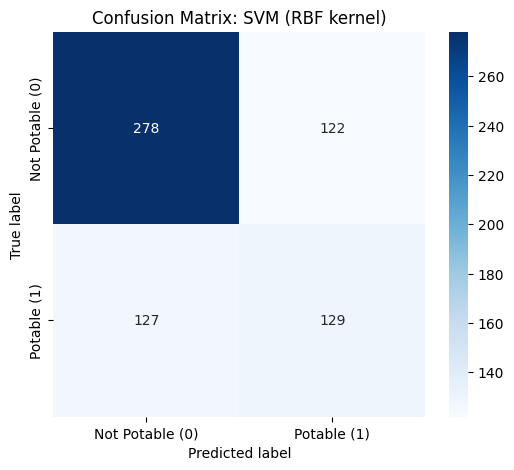

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Potable (0)", "Potable (1)"],
            yticklabels=["Not Potable (0)", "Potable (1)"])
plt.title("Confusion Matrix: SVM (RBF kernel)")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()

# OBSERVATIONS

1. Accuracy against the baseline

Accuracy is 407 / 656 = 62.0%.
A model that always predicts “not potable” would get 400 / 656 = 61.0%.
So the SVM beats the baseline by only about one percentage point.
Accuracy hides this because the classes are imbalanced, which is why per-class precision, recall and F1 matter.

2. The gap between the two classes

Not potable (0): precision about 0.69, recall about 0.70, F1 about 0.69. The model handles this class reasonably well.
Potable (1): precision about 0.51, recall about 0.50, F1 about 0.51.
When it predicts “potable” it’s right only about half the time (129 of 251), and it finds only about half of the truly potable samples (129 of 256). That is close to guessing.

3. False positives and why they matter

122 of the 400 unsafe samples (about 30%) were predicted as potable.
In a drinking-water setting this is the more dangerous mistake, because people could be told unsafe water is safe.
There were also 127 false negatives (potable water called unsafe). That error is less harmful but wasteful.
class_weight="balanced" makes the model predict “potable” more often (251 predictions against 256 true potable samples). That helps potable recall but increases false positives, so this is a trade-off to mention.

4. Likely causes and next steps

The EDA showed only weak correlation between each feature and potability, so the features may not separate the classes well. This is probably the main cause.
The classes overlap heavily in feature space, so even a curved boundary can’t split them cleanly.
The SVM used default settings (C = 1.0, gamma = “scale”) with no tuning.
Next steps: tune C and gamma with cross-validation (GridSearchCV), try other models such as a tuned Random Forest or a neural network, and revisit feature engineering. Also consider a threshold that favours fewer false positives if safety matters most.
One honest caveat: the dataset is known to be hard, and accuracy in the low 60s is typical for it, so a weak result isn’t necessarily a mistake in your pipeline.

## Model Comparison

Both models were trained on the same training set and evaluated on the same 656 test samples, so the comparison is fair. Because the classes are imbalanced (61% not potable), the potable-class metrics and the false positive counts are compared alongside accuracy. A model that always predicts "not potable" would score 61.0%.

In [45]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

cm_rf = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])
cm_svm = confusion_matrix(y_test, y_pred_svm, labels=[0, 1])

comparison = pd.DataFrame({
    "Model": ["Random Forest", "SVM (RBF)"],
    "Accuracy": [accuracy_score(y_test, y_pred_rf), accuracy_score(y_test, y_pred_svm)],
    "Precision (Potable)": [precision_score(y_test, y_pred_rf), precision_score(y_test, y_pred_svm)],
    "Recall (Potable)": [recall_score(y_test, y_pred_rf), recall_score(y_test, y_pred_svm)],
    "F1 (Potable)": [f1_score(y_test, y_pred_rf), f1_score(y_test, y_pred_svm)],
    "False Positives": [cm_rf[0, 1], cm_svm[0, 1]],
    "False Negatives": [cm_rf[1, 0], cm_svm[1, 0]],
}).round(3)

comparison

,Model,Accuracy,Precision (Potable),Recall (Potable),F1 (Potable),False Positives,False Negatives
0,Random Forest,0.671,0.682,0.293,0.410,35,181
1,SVM (RBF),0.620,0.514,0.504,0.509,122,127


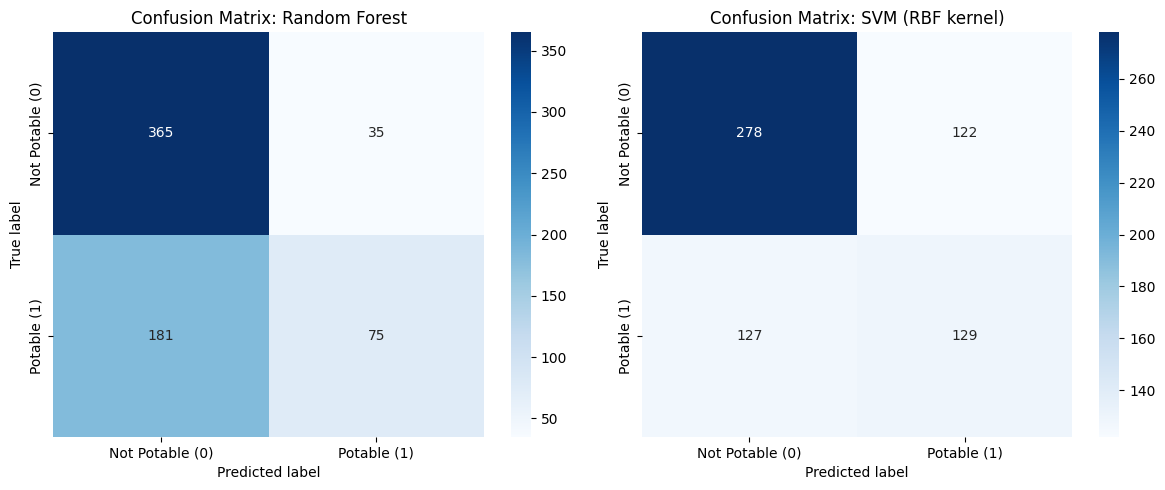

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, cm, title in zip(axes, [cm_rf, cm_svm], ["Random Forest", "SVM (RBF kernel)"]):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Not Potable (0)", "Potable (1)"],
                yticklabels=["Not Potable (0)", "Potable (1)"])
    ax.set_title(f"Confusion Matrix: {title}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
plt.tight_layout()
plt.show()

### Comparison Conclusion

Random Forest had the higher accuracy (0.671 against 0.620), beating the 61% baseline by about 6 points, while the SVM beat it by only about 1 point. The two models make different kinds of mistakes. Random Forest is cautious: it classified only 35 unsafe samples as safe (8.8% of the 400 unsafe samples) but found only 29% of the potable samples. The SVM found about 50% of the potable samples and had the higher potable F1 (0.509 against 0.410), but it classified 122 unsafe samples as safe (30.5%).

For drinking water, calling unsafe water safe is the more serious error, so Random Forest is the safer model here. If the goal were to find as much potable water as possible, the SVM would be preferred. Neither model is strong.

Limitations: both models used initial settings with no hyperparameter tuning, and the EDA showed weak relationships between the individual features and potability, which probably limits performance. Possible next steps are tuning with cross-validation, adjusting the decision threshold to reduce false positives, and trying a neural network.

## References

- Kadiwal, A. (n.d.). Water potability. Kaggle. https://www.kaggle.com/dataset/adityakadiwal/water-potability
- Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12, 2825–2830.
- Breiman, L. (2001). Random forests. Machine Learning, 45(1), 5–32.
- Cortes, C., & Vapnik, V. (1995). Support-vector networks. Machine Learning, 20(3), 273–297.
- Anthropic. (2026). Claude Sonnet 5.5 [Large language model]. https://claude.ai (used for code assistance, as acknowledged in the code comments)

In [47]:
import joblib, sklearn
joblib.dump(random_forest_model, "water_model.joblib")
print(sklearn.__version__)

1.6.1
